# 06 — Estimação ajustada com pesos de sobreposição (ATO) — São Paulo (capital), 2024
**IPT — Mestrado em Computação Aplicada**

Primeiro resultado **ajustado** da capital paulista: diferença de risco de baixo peso ao nascer entre início do pré-natal nos meses 1–3 (T=1) e nos meses 4–6 (T=0), ponderada por pesos de sobreposição (ATO). O resultado é uma **associação ajustada pelas covariáveis observadas**, não um efeito causal identificado.

Ponto de partida: [05b_comparabilidade_sp_capital_2024.ipynb](05b_comparabilidade_sp_capital_2024.ipynb), que mostrou desequilíbrio relevante em escolaridade, situação conjugal e idade; suporte comum amplo; e escore concentrado perto de 1 (≈ 91% de T=1), o que torna pesos do tipo $1/(1-e)$ instáveis e motiva a ponderação ATO. Aquelas análises não são repetidas aqui. Nenhum AIPW, pareamento ou outro estimador é executado. Execute com a **.venv do projeto**; o notebook não grava arquivos.

## Resumo executivo

Entre **114.694 nascidos vivos elegíveis**, os riscos ponderados ATO são **8,68% em T=1** e **10,42% em T=0**. A diferença é **−1,74 p.p.**, com **IC 95% bootstrap de −2,36 a −1,12 p.p.**; a sensibilidade com situação conjugal produz aproximadamente **−1,63 p.p.**

São associações ajustadas na população de sobreposição, sem identificação causal demonstrada. O notebook recalcula todos os resultados, inclusive as 1.000 réplicas, e confere a precisão publicada ao final. Nenhuma estimativa é recuperada de saídas salvas.

## 1. População e variáveis

**População (especificação B):** nascimentos de 2024, mãe residente no município de São Paulo (`CODMUNRES=355030`), gestação única (`GRAVIDEZ=1`), peso inteiro de 500 a 6.000 g; T=1 se `MESPRENAT` 1–3, T=0 se 4–6; **Y=1 se peso < 2.500 g**. Referência: 114.694 nascimentos. A consulta reaproveita a projeção congelada de `src/amostra.py`.

**Unidade e tempo:** um registro de nascido vivo, chave `contador` única no arquivo de 2024. A exposição refere-se ao início do pré-natal e o desfecho ao nascimento. Não há tempo zero prospectivo observado; covariáveis do parto são aproximações de condições pré-exposição, com limitações de mensuração e seleção. Não há modelo preditivo de desfecho.

**Covariáveis definidas antes da estimação** (todas registradas no parto e tratadas como aproximações de condições anteriores à exposição):

| Covariável | Codificação | Justificativa |
|---|---|---|
| Idade materna | anos (10–59) e **idade²** | desequilíbrio concentrado nas adolescentes; o termo quadrático permite relação não linear com o escore |
| Escolaridade (`ESCMAE2010`) | 0–5; 9/nulo → Ignorado | maior desequilíbrio observado; aproximação de posição socioeconômica |
| Raça/cor (`RACACORMAE`) | 1–5; 9/nulo → Ignorado | atributo estável |
| Paridade (`PARIDADE`) | nulípara / multípara | histórico anterior à gestação |
| Perdas fetais anteriores (`QTDFILMORT`) | 0 / 1 / 2 ou mais; 99/nulo → Ignorado | ver verificação abaixo |

**Fora do modelo principal:** situação conjugal (temporalidade mais frágil: pode mudar depois do início do pré-natal) — aparece apenas no diagnóstico de balanço, como covariável **não ajustada**; UF (constante); e todas as variáveis do parto ou posteriores à exposição (peso, idade gestacional, consultas, tipo de parto, Apgar, Kotelchuck, Robson), bloqueadas por `validar_colunas_propensity`. "Ignorado" é tratado como indicador de ausência, nunca como categoria substantiva.

### Ambiente, insumos e visualização

Execute do início ao fim com o kernel da **`.venv` deste projeto (Python 3.11)**, a partir da raiz do projeto ou de `notebooks/principal/`. No PowerShell: `& .\.venv\Scripts\Activate.ps1`. Dependências declaradas em [requirements.txt](../../requirements.txt). Os Parquets locais e os módulos de `src/` indicados no código são os únicos insumos computacionais; links para outros notebooks/documentos fornecem contexto, sem executar ou ler seus resultados.

Ambiente usado na reconstrução: Python 3.11.9; DuckDB 1.5.5; pandas 3.0.6; NumPy 2.4.6; scikit-learn 1.8.0; Plotly 6.9.0; Kaleido 1.4.0. Não há instalação ou download durante a execução.

Cada figura é produzida por código Plotly e salva na própria saída como `application/vnd.plotly.v1+json` e PNG. A exibição usa um pacote MIME explícito, sem depender do renderer padrão de uma sessão anterior. **A interatividade depende do suporte Plotly do visualizador**; o PNG serve à leitura estática. Gerar novamente o PNG requer o Chrome local utilizado pelo Kaleido. Nenhuma galeria HTML ou figura em `outputs/` é necessária.

In [1]:
from pathlib import Path
import sys
import time
import warnings
sys.dont_write_bytecode = True

import duckdb
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import sklearn
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
raiz = next(p for p in [cwd, *cwd.parents]
            if (p / "src" / "visualizacao.py").is_file()
            and (p / "data" / "processed").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
# _criar_views contém a projeção SQL congelada das covariáveis do contrato principal.
from src.amostra import _criar_views
from src.diagnosticos import construir_pipeline_propensity, validar_colunas_propensity
from src.visualizacao import CORES_IPT
from src.graficos import (COR_FAIXA, COR_GRADE, COR_REFERENCIA, COR_T0, COR_T1, COR_TEXTO,
                          FONTE_SINASC_2024, exibir_plotly, layout_academico)

PARQUET = raiz / "data" / "processed" / "sinasc_2024.parquet"
MUNICIPIO = "355030"
ESPERADO = {"n": 114_694, "t1": 104_576, "t0": 10_118}
SEMENTE = 20240925
B = 1000
assert PARQUET.is_file(), f"Base local ausente: {PARQUET}"

def fmt(valor, casas=0):
    """Número no padrão brasileiro (milhar com ponto, decimal com vírgula)."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")

print("Ambiente:", sys.executable)
print("Versões: DuckDB", duckdb.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

Ambiente: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml\.venv\Scripts\python.exe
Versões: DuckDB 1.5.5 | pandas 3.0.6 | scikit-learn 1.8.0


In [2]:
with duckdb.connect() as con:
    _criar_views(con, PARQUET)
    sql_view = con.execute(
        "SELECT sql FROM duckdb_views() WHERE view_name = 'amostra_principal'"
    ).fetchone()[0]
    projecao = sql_view[sql_view.index(" AS SELECT ") + 4: sql_view.index(" FROM fase1_base")]
    dados = con.execute(
        projecao
        + ", mesprenat_num, peso_num, try_cast(QTDFILMORT AS INTEGER) AS QTDFILMORT_NUM"
        + ", year(try_strptime(CAST(DTNASC AS VARCHAR), '%d%m%Y')) AS ano_nascimento"
        + " FROM fase1_base"
        + " WHERE tratamento IS NOT NULL AND y_p1 IS NOT NULL AND gravidez_num = 1"
        + " AND mesprenat_num BETWEEN 1 AND 6 AND CAST(CODMUNRES AS VARCHAR) = ?"
        + " ORDER BY contador", [MUNICIPIO]).df()

dados["tratamento"] = dados.tratamento.astype(int)
dados["Y_BAIXO_PESO"] = dados.Y_BAIXO_PESO.astype(int)
n_total, n_t1 = len(dados), int(dados.tratamento.sum())
n_t0 = n_total - n_t1
assert {"n": n_total, "t1": n_t1, "t0": n_t0} == ESPERADO, (n_total, n_t1, n_t0)
assert dados.contador.notna().all() and dados.contador.is_unique
assert dados.contador.is_monotonic_increasing
assert dados.ano_nascimento.notna().all() and dados.ano_nascimento.eq(2024).all()
assert int(dados.Y_BAIXO_PESO.sum()) == 9850
assert dados.tratamento.eq(dados.mesprenat_num.le(3).astype(int)).all()
assert dados.peso_num.between(500, 6000).all()
assert dados.Y_BAIXO_PESO.eq(dados.peso_num.lt(2500).astype(int)).all()
print(f"População: {fmt(n_total)} nascimentos | T=1 {fmt(n_t1)} | T=0 {fmt(n_t0)} | "
      f"casos de baixo peso {fmt(dados.Y_BAIXO_PESO.sum())}. Contagens conferidas com a referência.")

População: 114.694 nascimentos | T=1 104.576 | T=0 10.118 | casos de baixo peso 9.850. Contagens conferidas com a referência.


### Verificação de perdas fetais anteriores

`QTDFILMORT` é definido no dicionário como "número de perdas fetais e abortos" — história **anterior** à gestação atual, portanto temporalmente anterior à exposição. A inclusão depende de o campo estar bem preenchido e ter valores plausíveis na capital. Ressalvas que permanecem: o campo mistura perdas espontâneas e abortos (estes provavelmente sub-registrados), e limites/sentinelas (99) não estão confirmados no dicionário; a categorização 0 / 1 / 2 ou mais limita a influência de valores altos pouco plausíveis (10 ou mais), que entram em "2 ou mais".

In [3]:
q = dados.QTDFILMORT_NUM
verificacao = pd.Series({
    "nulo/não numérico": int(q.isna().sum()),
    "0": int(q.eq(0).sum()), "1": int(q.eq(1).sum()), "2": int(q.eq(2).sum()),
    "3–9": int(q.between(3, 9).sum()), "10–98": int(q.between(10, 98).sum()),
    "99 (sentinela não confirmada)": int(q.eq(99).sum()),
}, name="Nascimentos")
display(pd.DataFrame({"Nascimentos": verificacao.map(fmt),
                      "%": (100 * verificacao / n_total).map(lambda v: fmt(v, 3))}))
preenchido = 1 - (q.isna() | q.eq(99)).mean()
plausivel = q.between(0, 9).mean()
assert preenchido > 0.99 and plausivel > 0.99
print(f"Preenchido com valor não sentinela: {fmt(100 * preenchido, 2)}% | valores 0–9: {fmt(100 * plausivel, 2)}%."
      " Decisão: incluir no modelo principal, com as ressalvas acima.")

,Nascimentos,%
nulo/não numérico,28,"0,024"
0,89.570,"78,095"
1,19.502,"17,004"
2,4.167,"3,633"
3–9,1.415,"1,234"
10–98,12,"0,010"
99 (sentinela não confirmada),0,"0,000"


Preenchido com valor não sentinela: 99,98% | valores 0–9: 99,99%. Decisão: incluir no modelo principal, com as ressalvas acima.


## 2. Método de ponderação

1. **Escore de propensão** $e(X)=P(T=1\mid X)$: regressão logística com penalização L2 (C=1, variáveis numéricas padronizadas, categóricas em indicadores), **sem pesos de classe** — a sequência de processamento de `src/diagnosticos.py::construir_pipeline_propensity`. Com ~115 mil registros a penalização é praticamente desprezível e o intercepto não é penalizado, de modo que $\bar e \approx P(T=1)$ e as probabilidades mantêm a escala original. O escore é ajustado na amostra inteira (não fora da partição), pois a propriedade de balanço dos pesos ATO descrita no item 5 depende disso.
2. **Pesos de sobreposição:** $w_i = 1-e(X_i)$ se $T_i=1$; $w_i = e(X_i)$ se $T_i=0$. São limitados a $[0,1]$: não há divisão por $e$ ou $1-e$ e, portanto, não há pesos explosivos.
3. **Riscos ponderados** com pesos normalizados dentro de cada grupo: $\hat r_t=\sum_{i:T_i=t} w_i Y_i \big/ \sum_{i:T_i=t} w_i$. **Diferença ATO** $=\hat r_1-\hat r_0$, em pontos percentuais.
4. **População-alvo:** a ponderação compara os grupos na *população de sobreposição*, com densidade proporcional a $f(x)\,e(x)\,[1-e(x)]$ — ou seja, enfatiza perfis em que ambos os inícios de pré-natal são frequentes. **Não é** a população total (ATE) nem a dos tratados (ATT).
5. **Propriedade conhecida:** com escore logístico estimado por máxima verossimilhança sem penalização, as médias ponderadas de cada termo incluído no modelo seriam exatamente iguais entre os grupos (Li, Morgan e Zaslavsky, 2018). Com a penalização L2 usada aqui, ficam **aproximadamente** iguais (seção 4). Esse balanço nas covariáveis e nos termos do escore é esperado por construção e **não** demonstra ausência de confundimento; o diagnóstico informativo está nas variáveis fora do escore e no tamanho amostral efetivo.

Com um único modelo de escore e sem modelo de desfecho, o estimador **não é duplamente robusto**: sua validade depende de o modelo de propensão capturar a relação entre as covariáveis e T.

In [4]:
NUMERICAS = ["IDADEMAE_NUM", "IDADEMAE_QUAD"]
CATEGORICAS = ["ESCOLARIDADE_MAE", "RACA_COR_MAE", "PARIDADE_CAT", "PERDAS_FETAIS_CAT"]
validar_colunas_propensity([*NUMERICAS, *CATEGORICAS])
dados["IDADEMAE_QUAD"] = dados.IDADEMAE_NUM ** 2
assert dados.IDADEMAE_NUM.notna().all(), "Idade fora de 10–59 exigiria imputação documentada."

X = dados[[*NUMERICAS, *CATEGORICAS]]
T = dados.tratamento.to_numpy(dtype=int)
Y = dados.Y_BAIXO_PESO.to_numpy(dtype=int)
PIPELINE = construir_pipeline_propensity(NUMERICAS, CATEGORICAS)

def estimar_ato(x, t, y):
    """Reajusta o escore, calcula pesos de sobreposição e riscos normalizados por grupo."""
    modelo = clone(PIPELINE)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(x, t)
    convergiu = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)
    e = modelo.predict_proba(x)[:, 1]
    w = np.where(t == 1, 1 - e, e)
    r1 = np.average(y[t == 1], weights=w[t == 1])
    r0 = np.average(y[t == 0], weights=w[t == 0])
    return {"e": e, "w": w, "r1": r1, "r0": r0, "convergiu": convergiu, "modelo": modelo}

inicio = time.time()
ajuste = estimar_ato(X, T, Y)
assert ajuste["convergiu"], "Escore de propensão não convergiu."
e, w = ajuste["e"], ajuste["w"]
print(f"Escore ajustado em {fmt(time.time() - inicio, 1)} s; iterações: {int(ajuste['modelo']['modelo'].n_iter_.max())}.")
print(f"Média do escore {fmt(e.mean(), 4)} versus proporção observada de T=1 {fmt(T.mean(), 4)}.")

Escore ajustado em 1,2 s; iterações: 81.
Média do escore 0,9118 versus proporção observada de T=1 0,9118.


### Suporte empírico com as covariáveis finais

O suporte é reexaminado porque o conjunto de covariáveis mudou em relação à etapa anterior (sai situação conjugal; entra idade²). **Não se aplica o recorte simétrico 0,05–0,95.** Regra fixada antes de calcular qualquer risco: nenhum recorte automático; contar os registros fora do suporte comum observado e sua participação na soma dos pesos ATO de cada grupo. Exclusão só seria considerada se essa participação fosse relevante — o que é improvável, pois os pesos ATO são limitados a $[0,1]$ e registros nas caudas recebem peso pequeno no grupo em que são maioria.

In [5]:
e1, e0 = e[T == 1], e[T == 0]
suporte = (max(e1.min(), e0.min()), min(e1.max(), e0.max()))
fora = (e < suporte[0]) | (e > suporte[1])
percentis = [0, 1, 5, 25, 50, 75, 95, 99, 100]
display(pd.DataFrame({
    "T=1 (meses 1–3)": [fmt(np.percentile(e1, p), 4) for p in percentis],
    "T=0 (meses 4–6)": [fmt(np.percentile(e0, p), 4) for p in percentis],
}, index=["Mínimo", "P1", "P5", "P25", "Mediana", "P75", "P95", "P99", "Máximo"]))
peso_fora = {g: w[fora & (T == g)].sum() / w[T == g].sum() for g in (1, 0)}
print(f"Suporte comum observado: {fmt(suporte[0], 4)} a {fmt(suporte[1], 4)}.")
print(f"Fora do suporte: {fmt((fora & (T == 1)).sum())} de T=1 e {fmt((fora & (T == 0)).sum())} de T=0; "
      f"participação na soma dos pesos: T=1 {fmt(100 * peso_fora[1], 3)}%, T=0 {fmt(100 * peso_fora[0], 3)}%.")
n_excluidos = 0
print(f"Decisão: nenhuma exclusão ({n_excluidos} registros). A população-alvo é a de sobreposição definida pelos pesos ATO.")

,T=1 (meses 1–3),T=0 (meses 4–6)
Mínimo,"0,6232","0,6910"
P1,"0,8027","0,7732"
P5,"0,8450","0,8192"
P25,"0,8870","0,8678"
Mediana,"0,9124","0,8936"
P75,"0,9530","0,9169"
P95,"0,9719","0,9643"
P99,"0,9725","0,9719"
Máximo,"0,9760","0,9760"


Suporte comum observado: 0,6910 a 0,9760.
Fora do suporte: 6 de T=1 e 0 de T=0; participação na soma dos pesos: T=1 0,022%, T=0 0,000%.
Decisão: nenhuma exclusão (0 registros). A população-alvo é a de sobreposição definida pelos pesos ATO.


## 3. Pesos e tamanho amostral efetivo

Tamanho amostral efetivo de Kish por grupo: $n_{ef}=(\sum w_i)^2/\sum w_i^2$. A participação máxima é o maior peso individual dividido pela soma dos pesos do grupo.

In [6]:
def resumo_pesos(wg):
    return {"n": len(wg), "n efetivo (Kish)": wg.sum() ** 2 / (wg ** 2).sum(),
            "mínimo": wg.min(), "P1": np.percentile(wg, 1), "mediana": np.median(wg),
            "P99": np.percentile(wg, 99), "máximo": wg.max(), "participação máxima (%)": 100 * wg.max() / wg.sum()}
pesos = pd.DataFrame({"T=1 (peso 1−e)": resumo_pesos(w[T == 1]), "T=0 (peso e)": resumo_pesos(w[T == 0])})
ess = pesos.loc["n efetivo (Kish)"]
pesos_exib = pesos.copy().astype(object)
for linha in pesos.index:
    casas = 0 if linha in ("n", "n efetivo (Kish)") else 4
    pesos_exib.loc[linha] = pesos.loc[linha].map(lambda v: fmt(v, casas))
pesos_exib.loc["n efetivo / n (%)"] = (100 * ess / pesos.loc["n"]).map(lambda v: fmt(v, 1))
display(pesos_exib)

,T=1 (peso 1−e),T=0 (peso e)
n,104.576,10.118
n efetivo (Kish),84.995,10.096
mínimo,"0,0240","0,6910"
P1,"0,0275","0,7732"
mediana,"0,0876","0,8936"
P99,"0,1973","0,9719"
máximo,"0,3768","0,9760"
participação máxima (%),"0,0042","0,0108"
n efetivo / n (%),"81,3","99,8"


### Distribuição do escore e efeito dos pesos

Distribuição do escore de propensão em cada grupo, sem ponderação (esquerda) e com os pesos ATO (direita). Barras para cima: T=1; para baixo: T=0; cada grupo em percentual do próprio total (de registros ou da soma dos pesos). O peso de cada registro é função direta do escore, $1-e$ em T=1 e $e$ em T=0, e aparece no hover. A ponderação reduz a influência das caudas e aproxima as distribuições do escore nos dois grupos. Isso descreve a população de sobreposição; não torna os grupos iguais em variáveis fora do escore (ver situação conjugal na seção 4).

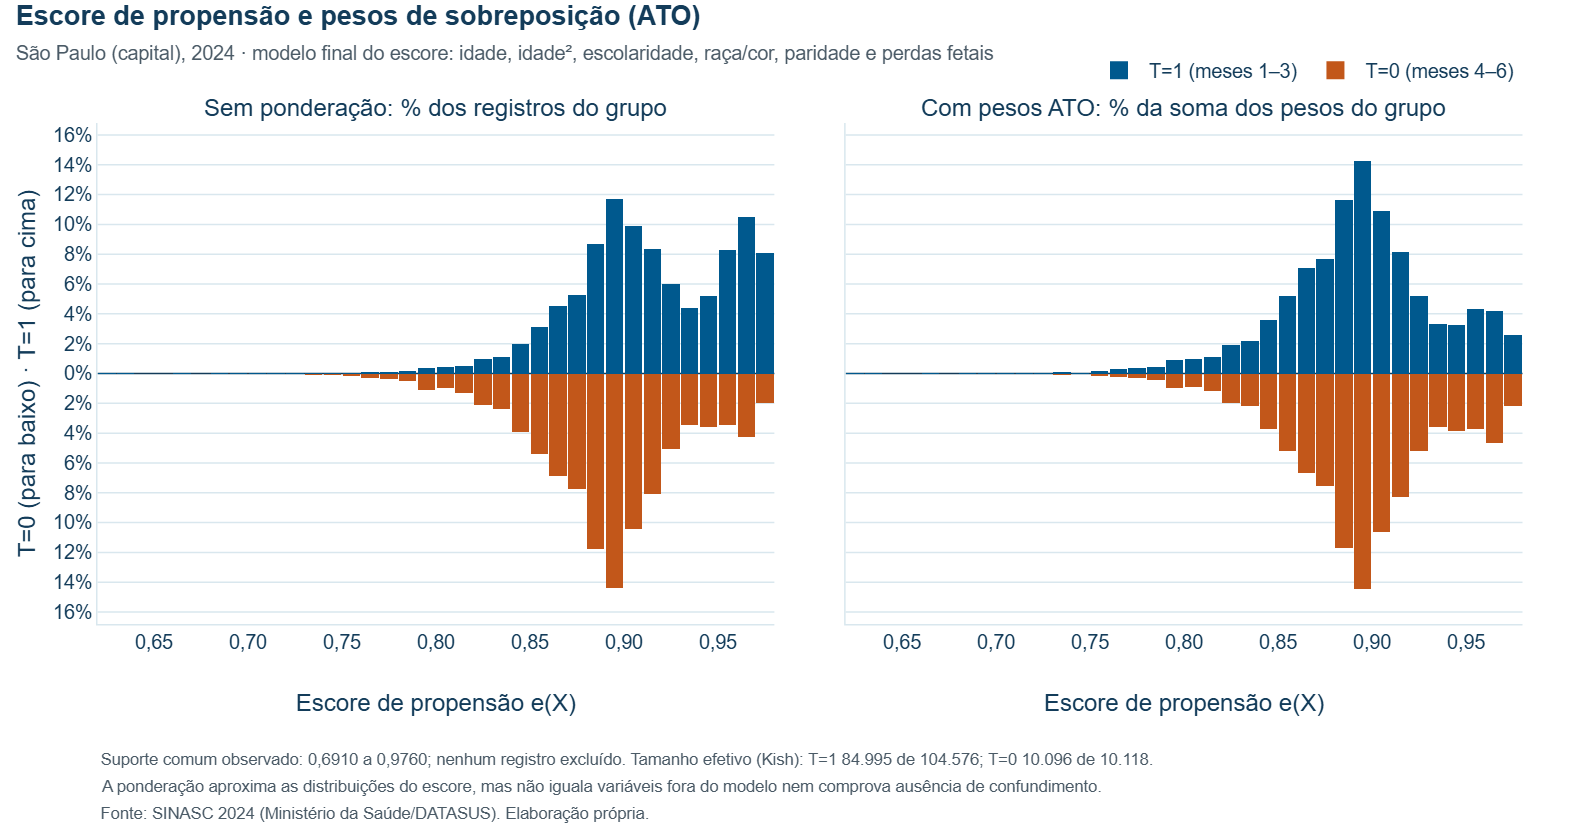

In [7]:
# Escore e pesos ATO por faixa de 0,01, em percentual de cada grupo (registros ou soma dos pesos).
bordas = np.round(np.arange(np.floor(e.min() * 100) / 100, np.ceil(e.max() * 100) / 100 + 0.005, 0.01), 2)
centros = (bordas[:-1] + bordas[1:]) / 2
faixas = [f"{fmt(a, 2)} a {fmt(b, 2)}" for a, b in zip(bordas[:-1], bordas[1:])]
fig_escore = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.05,
                           subplot_titles=("Sem ponderação: % dos registros do grupo",
                                           "Com pesos ATO: % da soma dos pesos do grupo"))
maximo = 0
for g, nome, cor, sinal in [(1, "T=1 (meses 1–3)", COR_T1, 1), (0, "T=0 (meses 4–6)", COR_T0, -1)]:
    eg, wg = e[T == g], w[T == g]
    n_faixa, _ = np.histogram(eg, bins=bordas)
    w_faixa, _ = np.histogram(eg, bins=bordas, weights=wg)
    pct_n, pct_w = 100 * n_faixa / len(eg), 100 * w_faixa / wg.sum()
    maximo = max(maximo, pct_n.max(), pct_w.max())
    peso_faixa = 1 - centros if g == 1 else centros
    regra = "1 − e(X)" if g == 1 else "e(X)"
    dados_faixa = [[fx, float(pn), int(nf), float(pw), float(pf)]
                   for fx, pn, nf, pw, pf in zip(faixas, pct_n, n_faixa, pct_w, peso_faixa)]
    for coluna, pct in [(1, pct_n), (2, pct_w)]:
        fig_escore.add_bar(
            x=centros, y=sinal * pct, width=0.0092, marker_color=cor, name=nome, legendgroup=nome,
            showlegend=coluna == 1, row=1, col=coluna, customdata=dados_faixa,
            hovertemplate=(f"<b>{nome}</b><br>Escore e(X): %{{customdata[0]}}<br>"
                           "Registros: %{customdata[2]:,.0f} (%{customdata[1]:.2f}% do grupo)<br>"
                           "Soma dos pesos ATO: %{customdata[3]:.2f}% do grupo<br>"
                           f"Peso ATO na faixa ≈ %{{customdata[4]:.2f}} ({regra})<extra></extra>"))
passo = 2 if maximo < 16 else 5
limite = passo * np.ceil(maximo / passo)
marcas = np.arange(-limite, limite + passo, passo)
fig_escore.update_yaxes(tickvals=marcas, ticktext=[fmt(abs(v), 0) + "%" for v in marcas],
                        range=[-limite * 1.05, limite * 1.05], zeroline=True, zerolinecolor=COR_TEXTO)
fig_escore.update_yaxes(title="T=0 (para baixo) · T=1 (para cima)", row=1, col=1)
fig_escore.update_xaxes(title="Escore de propensão e(X)", tickformat=".2f", dtick=0.05)
layout_academico(
    fig_escore, "Escore de propensão e pesos de sobreposição (ATO)",
    "São Paulo (capital), 2024 · modelo final do escore: idade, idade², escolaridade, raça/cor, paridade e perdas fetais",
    notas=[f"Suporte comum observado: {fmt(suporte[0], 4)} a {fmt(suporte[1], 4)}; nenhum registro excluído. "
           f"Tamanho efetivo (Kish): T=1 {fmt(ess.iloc[0])} de {fmt(n_t1)}; T=0 {fmt(ess.iloc[1])} de {fmt(n_t0)}.",
           "A ponderação aproxima as distribuições do escore, mas não iguala variáveis fora do modelo nem comprova ausência "
           "de confundimento.", FONTE_SINASC_2024],
    nome_arquivo="06_escore_pesos_ato", altura=560)
fig_escore.update_layout(barmode="overlay", bargap=0,
                         legend=dict(orientation="h", x=1, xanchor="right", y=1.06, yanchor="bottom"))
exibir_plotly(fig_escore)


## 4. Balanço antes e depois da ponderação

SMD = (média em T=1 − média em T=0) / desvio-padrão combinado **não ponderado** $\sqrt{(s_1^2+s_0^2)/2}$. O denominador é o mesmo antes e depois, para que a comparação reflita apenas a mudança nas médias. Categóricas: um indicador por nível (inclusive Ignorado). Situação conjugal **não está no modelo**: suas linhas mostram o desequilíbrio que sobra numa covariável não ajustada.

In [8]:
ROTULOS = {
    "ESCOLARIDADE_MAE": ("Escolaridade", {"0": "Sem escolaridade", "1": "Fundamental I", "2": "Fundamental II",
                         "3": "Médio", "4": "Superior incompleto", "5": "Superior completo"}),
    "RACA_COR_MAE": ("Raça/cor", {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena"}),
    "PARIDADE_CAT": ("Paridade", {"0": "Nulípara", "1": "Multípara"}),
    "PERDAS_FETAIS_CAT": ("Perdas fetais anteriores", {"0": "Nenhuma", "1": "Uma", "2_OU_MAIS": "Duas ou mais"}),
    "SITUACAO_CONJUGAL": ("Situação conjugal (não ajustada)", {"1": "Solteira", "2": "Casada", "3": "Viúva",
                          "4": "Separada/divorciada", "5": "União estável"}),
}
colunas_bal = {("Idade materna (anos)", "média"): dados.IDADEMAE_NUM.to_numpy(float),
               ("Idade materna²", "média"): dados.IDADEMAE_QUAD.to_numpy(float),
               ("Idade materna (descritiva)", "10–19 anos"): dados.IDADEMAE_NUM.le(19).to_numpy(float)}
for var, (nome, niveis) in ROTULOS.items():
    for nivel in sorted(dados[var].unique(), key=lambda n: (n == "IGNORADO", n)):
        colunas_bal[(nome, niveis.get(nivel, "Ignorado/ausente"))] = dados[var].eq(nivel).to_numpy(float)

def balancear(colunas, pesos):
    linhas = []
    for (variavel, nivel), v in colunas.items():
        v1, v0 = v[T == 1], v[T == 0]
        dp = np.sqrt((v1.var(ddof=1) + v0.var(ddof=1)) / 2)
        m1w, m0w = np.average(v1, weights=pesos[T == 1]), np.average(v0, weights=pesos[T == 0])
        linhas.append({"variavel": variavel, "nivel": nivel,
                       "media_t1": v1.mean(), "media_t0": v0.mean(), "media_t1_pond": m1w, "media_t0_pond": m0w,
                       "smd_antes": (v1.mean() - v0.mean()) / dp if dp else 0.0,
                       "smd_depois": (m1w - m0w) / dp if dp else 0.0})
    return pd.DataFrame(linhas)

balanco = balancear(colunas_bal, w)
balanco["ajustada"] = ~balanco.variavel.str.contains("não ajustada|descritiva")
ajustadas = balanco.loc[balanco.ajustada]
nao_ajustadas = balanco.loc[~balanco.ajustada]

exib = balanco.copy()
for c in ["media_t1", "media_t0", "media_t1_pond", "media_t0_pond"]:
    exib[c] = [fmt(v, 1) if n == "média" else fmt(100 * v, 1) + "%" for v, n in zip(balanco[c], balanco.nivel)]
for c in ["smd_antes", "smd_depois"]:
    exib[c] = balanco[c].map(lambda v: fmt(v, 3))
exib.columns = ["Variável", "Nível", "T=1 bruto", "T=0 bruto", "T=1 ATO", "T=0 ATO",
                "SMD antes", "SMD depois", "ajustada"]
with pd.option_context("display.max_rows", 100):
    display(exib.drop(columns="ajustada").set_index(["Variável", "Nível"]))

print(f"Covariáveis ajustadas — |SMD| máximo: antes {fmt(ajustadas.smd_antes.abs().max(), 3)}, "
      f"depois {fmt(ajustadas.smd_depois.abs().max(), 4)}.")
print(f"Não ajustadas/descritivas — |SMD| máximo: antes {fmt(nao_ajustadas.smd_antes.abs().max(), 3)}, "
      f"depois {fmt(nao_ajustadas.smd_depois.abs().max(), 3)}.")

T=1 bruto T=0 bruto  \
Variável                         Nível                                     
Idade materna (anos)             média                    29,3      27,5   
Idade materna²                   média                   902,3     802,4   
Idade materna (descritiva)       10–19 anos               6,6%     11,9%   
Escolaridade                     Sem escolaridade         0,0%      0,0%   
                                 Fundamental I            0,6%      1,1%   
                                 Fundamental II           8,3%     14,9%   
                                 Médio                   54,0%     65,4%   
                                 Superior incompleto      5,9%      5,6%   
                                 Superior completo       31,1%     12,9%   
                                 Ignorado/ausente         0,0%      0,1%   
Raça/cor                         Branca                  45,9%     36,1%   
                                 Preta                   10,9%     12,7%   
                                 Amarela                  1,1%      0,6%   
                                 Parda                   41,9%     50,3%   
                                 Indígena                 0,1%      0,3%   
                                 Ignorado/ausente         0,0%      0,0%   
Paridade                         Nulípara                40,4%     32,4%   
                                 Multípara               59,6%     67,6%   
Perdas fetais anteriores         Nenhuma                 78,0%     79,5%   
                                 Uma                     17,1%     15,6%   
                                 Duas ou mais             4,9%      4,9%   
                                 Ignorado/ausente         0,0%      0,0%   
Situação conjugal (não ajustada) Solteira                45,3%     59,1%   
                                 Casada                  36,5%     18,1%   
                                 Viúva                    0,1%      0,1%   
                                 Separada/divorciada      1,8%      1,5%   
                                 União estável           16,3%     21,2%   
                                 Ignorado/ausente         0,1%      0,0%   

                                                     T=1 ATO T=0 ATO  \
Variável                         Nível                                 
Idade materna (anos)             média                  27,6    27,6   
Idade materna²                   média                 810,8   810,8   
Idade materna (descritiva)       10–19 anos            11,1%   11,3%   
Escolaridade                     Sem escolaridade       0,0%    0,0%   
                                 Fundamental I          1,0%    1,0%   
                                 Fundamental II        14,1%   14,1%   
                                 Médio                 65,2%   65,2%   
                                 Superior incompleto    5,7%    5,7%   
                                 Superior completo     13,8%   13,8%   
                                 Ignorado/ausente       0,0%    0,1%   
Raça/cor                         Branca                36,7%   36,7%   
                                 Preta                 12,7%   12,6%   
                                 Amarela                0,6%    0,6%   
                                 Parda                 49,7%   49,8%   
                                 Indígena               0,2%    0,2%   
                                 Ignorado/ausente       0,0%    0,0%   
Paridade                         Nulípara              32,9%   32,9%   
                                 Multípara             67,1%   67,1%   
Perdas fetais anteriores         Nenhuma               79,2%   79,2%   
                                 Uma                   15,9%   15,9%   
                                 Duas ou mais           4,9%    4,9%   
                                 Ignorado/ausente       0,0%    0,0%   
Situação conjugal (não ajustada) Solteira   

Covariáveis ajustadas — |SMD| máximo: antes 0,452, depois 0,0031.
Não ajustadas/descritivas — |SMD| máximo: antes 0,421, depois 0,194.


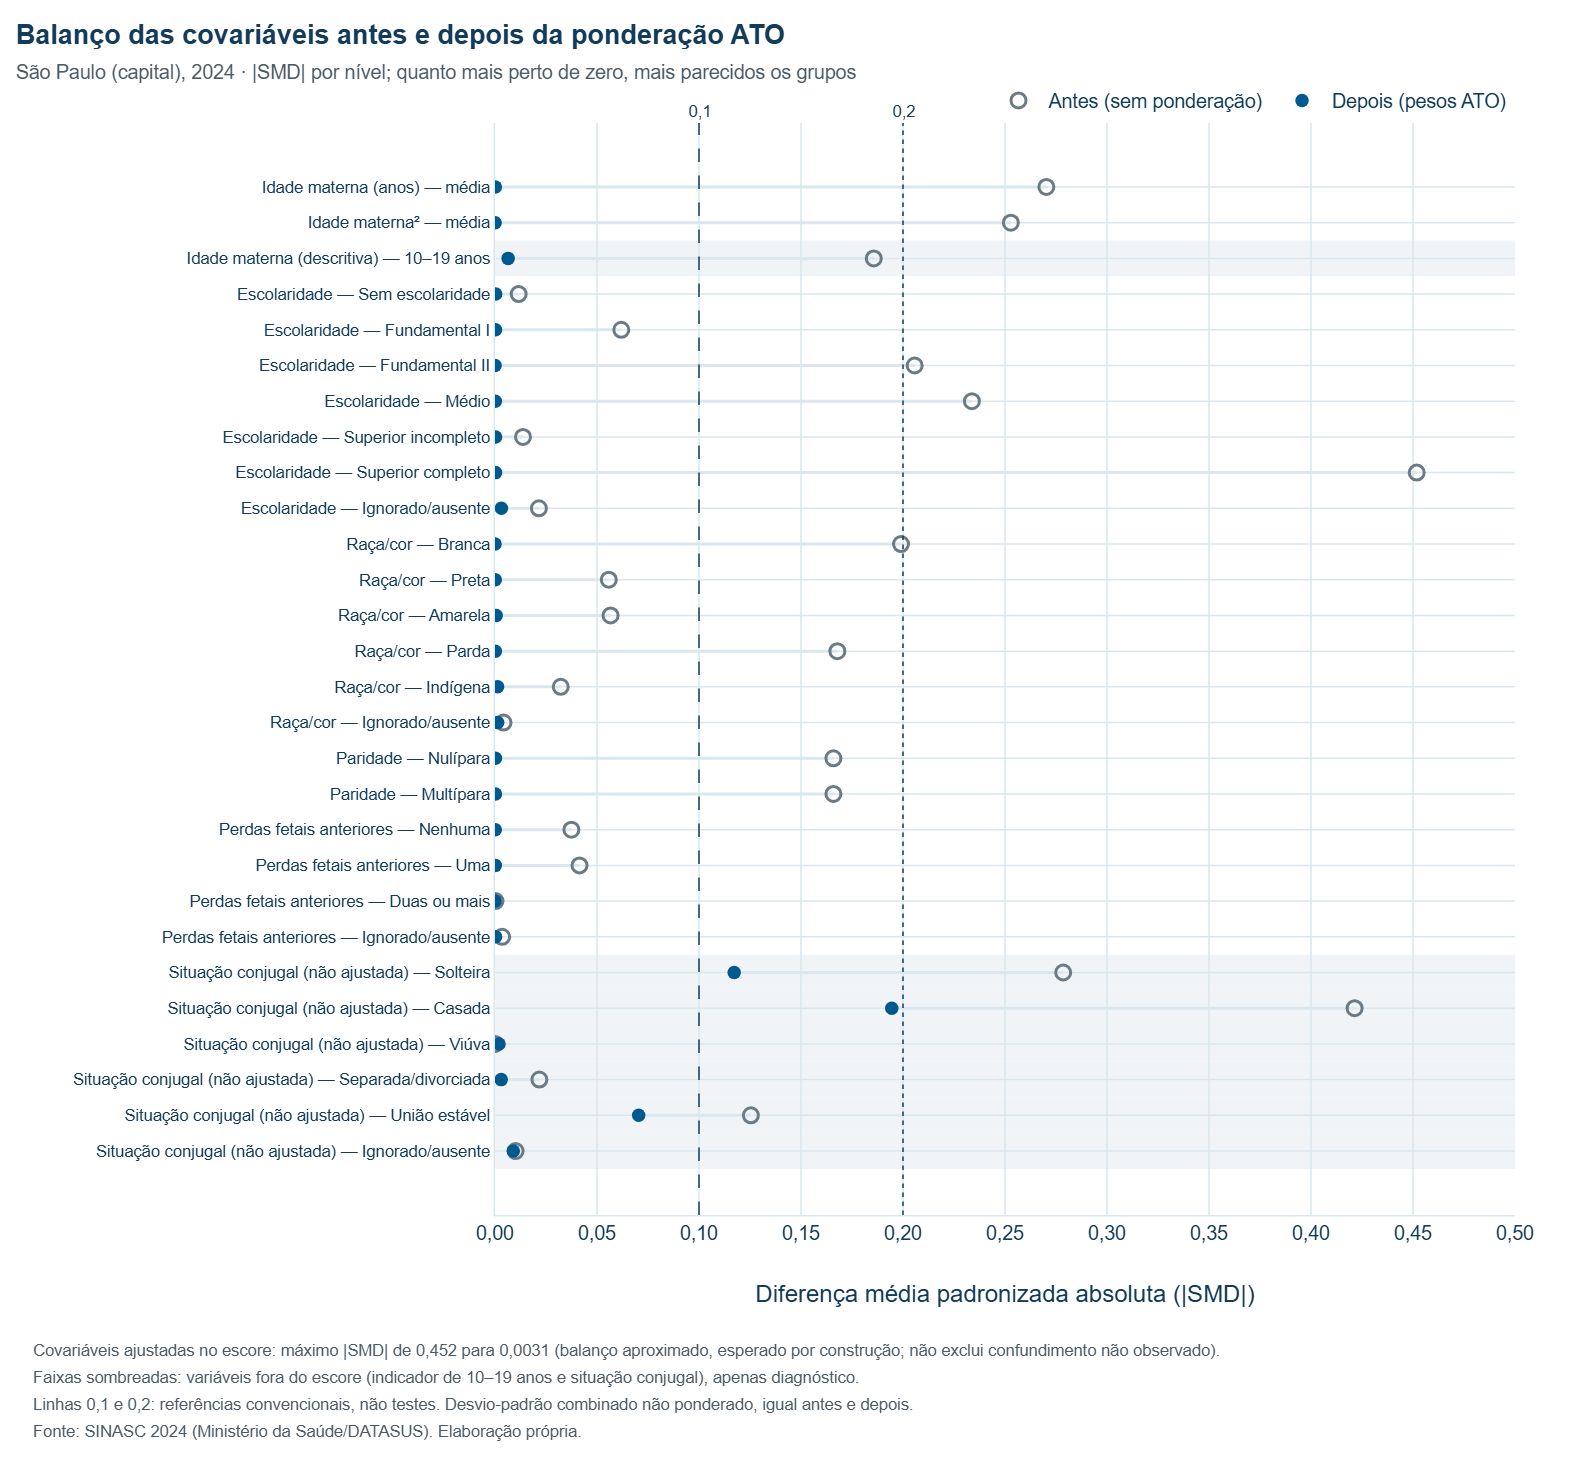

In [9]:
plot = balanco.copy()
plot["rotulo"] = [f"{v} — {n}" for v, n in zip(plot.variavel, plot.nivel)]
ordem = plot.rotulo.tolist()[::-1]   # primeira linha da tabela no topo do gráfico

def valor_exibido(v, nivel):
    return fmt(v, 1) if nivel == "média" else fmt(100 * v, 1) + "%"

detalhe = [["Covariável ajustada no escore" if r.ajustada else "Fora do escore: apenas diagnóstico",
            valor_exibido(r.media_t1, r.nivel), valor_exibido(r.media_t0, r.nivel),
            valor_exibido(r.media_t1_pond, r.nivel), valor_exibido(r.media_t0_pond, r.nivel),
            float(r.smd_antes), float(r.smd_depois)] for r in plot.itertuples()]
hover = ("<b>%{y}</b><br>%{customdata[0]}<br>"
         "T=1: %{customdata[1]} bruto → %{customdata[3]} ponderado<br>"
         "T=0: %{customdata[2]} bruto → %{customdata[4]} ponderado<br>"
         "SMD (T=1 − T=0): antes %{customdata[5]:.3f} · depois %{customdata[6]:.4f}<extra></extra>")

fig_bal = go.Figure()
for r in plot.itertuples():
    if not r.ajustada:   # faixa de fundo nas linhas fora do escore
        pos = ordem.index(r.rotulo)
        fig_bal.add_shape(type="rect", xref="paper", x0=0, x1=1, yref="y", y0=pos - 0.5, y1=pos + 0.5,
                          fillcolor=COR_FAIXA, line_width=0, layer="below")
conectores_x, conectores_y = [], []
for r in plot.itertuples():
    conectores_x += [abs(r.smd_antes), abs(r.smd_depois), None]
    conectores_y += [r.rotulo, r.rotulo, None]
fig_bal.add_scatter(x=conectores_x, y=conectores_y, mode="lines", line=dict(color=COR_GRADE, width=2),
                    hoverinfo="skip", showlegend=False)
fig_bal.add_scatter(x=plot.smd_antes.abs(), y=plot.rotulo, mode="markers", name="Antes (sem ponderação)",
                    marker=dict(color=COR_REFERENCIA, symbol="circle-open", size=10, line=dict(width=2)),
                    customdata=detalhe, hovertemplate=hover)
fig_bal.add_scatter(x=plot.smd_depois.abs(), y=plot.rotulo, mode="markers", name="Depois (pesos ATO)",
                    marker=dict(color=COR_T1, symbol="circle", size=9),
                    customdata=detalhe, hovertemplate=hover)
for limite, traco in [(0.1, "dash"), (0.2, "dot")]:
    fig_bal.add_vline(x=limite, line=dict(color=COR_TEXTO, dash=traco, width=1),
                      annotation_text=fmt(limite, 1), annotation_position="top", annotation_font_size=11)
layout_academico(
    fig_bal, "Balanço das covariáveis antes e depois da ponderação ATO",
    "São Paulo (capital), 2024 · |SMD| por nível; quanto mais perto de zero, mais parecidos os grupos",
    notas=[f"Covariáveis ajustadas no escore: máximo |SMD| de {fmt(ajustadas.smd_antes.abs().max(), 3)} para "
           f"{fmt(ajustadas.smd_depois.abs().max(), 4)} (balanço aproximado, esperado por construção; não exclui confundimento "
           "não observado).",
           "Faixas sombreadas: variáveis fora do escore (indicador de 10–19 anos e situação conjugal), apenas diagnóstico.",
           "Linhas 0,1 e 0,2: referências convencionais, não testes. Desvio-padrão combinado não ponderado, igual antes e depois.",
           FONTE_SINASC_2024],
    nome_arquivo="06_balanco_smd", altura=24 * len(plot) + 300, margem_esquerda=330)
fig_bal.update_layout(legend=dict(orientation="h", x=1, xanchor="right", y=1.0, yanchor="bottom"))
fig_bal.update_xaxes(title="Diferença média padronizada absoluta (|SMD|)",
                     range=[0, max(0.5, plot.smd_antes.abs().max() * 1.1)], dtick=0.05, tickformat=".2f")
fig_bal.update_yaxes(categoryorder="array", categoryarray=ordem, tickfont=dict(size=11))
exibir_plotly(fig_bal)


### Quem é a população-alvo da ponderação

A tabela separa dois tipos de variável. **Covariáveis ajustadas** (idade e idade², escolaridade, raça/cor, paridade e perdas fetais) entram no escore; nelas, as médias ponderadas de T=1 e T=0 ficam aproximadamente iguais (máximo |SMD| 0,0031), e as duas colunas ponderadas descrevem, de forma aproximada, o perfil da população de sobreposição. **Variáveis de diagnóstico** ficam fora do escore e servem para verificar o que a ponderação não equilibra: a situação conjugal continua diferente entre os grupos ponderados e deve ser lida separadamente em T=1 e T=0, sem uma proporção única para a população de sobreposição. O indicador de 10–19 anos é descritivo (a idade entra no escore pelos termos linear e quadrático). A comparação com a população total mostra para quem o resultado vale.

In [10]:
perfil_itens = [("Idade materna (anos)", "média"), ("Idade materna (descritiva)", "10–19 anos"),
                ("Escolaridade", "Fundamental II"), ("Escolaridade", "Médio"), ("Escolaridade", "Superior completo"),
                ("Raça/cor", "Branca"), ("Raça/cor", "Parda"), ("Raça/cor", "Preta"),
                ("Paridade", "Nulípara"), ("Perdas fetais anteriores", "Nenhuma"),
                ("Situação conjugal (não ajustada)", "Casada")]
perfil = balanco.set_index(["variavel", "nivel"]).loc[perfil_itens]
total = {k: colunas_bal[k].mean() for k in perfil_itens}
def f(v, k):
    return fmt(v, 1) if k[1] == "média" else fmt(100 * v, 1) + "%"
def papel(k):
    if "descritiva" in k[0]:
        return "descritiva (idade e idade² no escore)"
    return "ajustada no escore" if perfil.loc[k, "ajustada"] else "fora do escore (diagnóstico)"
display(pd.DataFrame({
    "Papel no ajuste": [papel(k) for k in perfil_itens],
    "População total": [f(total[k], k) for k in perfil_itens],
    "T=1 bruto": [f(perfil.loc[k, "media_t1"], k) for k in perfil_itens],
    "T=0 bruto": [f(perfil.loc[k, "media_t0"], k) for k in perfil_itens],
    "T=1 ponderado (ATO)": [f(perfil.loc[k, "media_t1_pond"], k) for k in perfil_itens],
    "T=0 ponderado (ATO)": [f(perfil.loc[k, "media_t0_pond"], k) for k in perfil_itens],
}, index=pd.MultiIndex.from_tuples(perfil_itens, names=["Variável", "Nível"])))
casada = perfil.loc[("Situação conjugal (não ajustada)", "Casada")]
print(f"Situação conjugal, fora do escore: casadas são {fmt(100 * casada.media_t1_pond, 1)}% em T=1 e "
      f"{fmt(100 * casada.media_t0_pond, 1)}% em T=0 após a ponderação (SMD {fmt(casada.smd_depois, 3)}); "
      "não há uma proporção única para a população de sobreposição nessa variável.")


Papel no ajuste  \
Variável                         Nível                                                      
Idade materna (anos)             média                                 ajustada no escore   
Idade materna (descritiva)       10–19 anos         descritiva (idade e idade² no escore)   
Escolaridade                     Fundamental II                        ajustada no escore   
                                 Médio                                 ajustada no escore   
                                 Superior completo                     ajustada no escore   
Raça/cor                         Branca                                ajustada no escore   
                                 Parda                                 ajustada no escore   
                                 Preta                                 ajustada no escore   
Paridade                         Nulípara                              ajustada no escore   
Perdas fetais anteriores         Nenhuma                               ajustada no escore   
Situação conjugal (não ajustada) Casada                      fora do escore (diagnóstico)   

                                                   População total T=1 bruto  \
Variável                         Nível                                         
Idade materna (anos)             média                        29,1      29,3   
Idade materna (descritiva)       10–19 anos                   7,1%      6,6%   
Escolaridade                     Fundamental II               8,9%      8,3%   
                                 Médio                       55,0%     54,0%   
                                 Superior completo           29,5%     31,1%   
Raça/cor                         Branca                      45,0%     45,9%   
                                 Parda                       42,7%     41,9%   
                                 Preta                       11,1%     10,9%   
Paridade                         Nulípara                    39,7%     40,4%   
Perdas fetais anteriores         Nenhuma                     78,1%     78,0%   
Situação conjugal (não ajustada) Casada                      34,8%     36,5%   

                                                   T=0 bruto  \
Variável                         Nível                         
Idade materna (anos)             média                  27,5   
Idade materna (descritiva)       10–19 anos            11,9%   
Escolaridade                     Fundamental II        14,9%   
                                 Médio                 65,4%   
                                 Superior completo     12,9%   
Raça/cor                         Branca                36,1%   
                                 Parda                 50,3%   
                                 Preta                 12,7%   
Paridade                         Nulípara              32,4%   
Perdas fetais anteriores         Nenhuma               79,5%   
Situação conjugal (não ajustada) Casada                18,1%   

                                                   T=1 ponderado (ATO)  \
Variável                         Nível                                   
Idade materna (anos)             média                            27,6   
Idade materna (descritiva)       10–19 anos                      11,1%   
Escolaridade                     Fundamental II                  14,1%   
                                 Médio                           65,2%   
                                 Superior completo               13,8%   
Raça/cor                         Branca                          36,7%   
                                 Parda                           49,7%   
                                 Preta                           12,7%   
Paridade                         Nulípara                        32,9%   
Perdas fetais anteriores         Nenhuma                         79,2%   
Situação conjugal (não ajustada) Casada                          27,1%   

                           

Situação conjugal, fora do escore: casadas são 27,1% em T=1 e 18,6% em T=0 após a ponderação (SMD 0,194); não há uma proporção única para a população de sobreposição nessa variável.


## 5. Riscos brutos e ponderados

**Intervalos de confiança de 95%: bootstrap não paramétrico com reestimação do escore.** Em cada uma das B=1.000 réplicas, os 114.694 nascimentos são reamostrados com reposição; o escore de propensão é **reajustado** na réplica (mesma especificação), os pesos são recalculados e os riscos e diferenças são reestimados. O intervalo é o percentil 2,5–97,5 das réplicas; o erro-padrão bootstrap e o intervalo normal correspondente são mostrados como conferência. Sementes derivadas de `SeedSequence(20240925)`, uma por réplica, de modo que o resultado não depende do número de processos paralelos.

**Limitação do intervalo:** a reamostragem trata os nascimentos como independentes; não considera agrupamento por estabelecimento ou mães com mais de um parto no ano, que tendem a ampliar a incerteza. O intervalo cobre apenas a variabilidade amostral, não vieses de confundimento, mensuração ou seleção.

In [11]:
risco_bruto = {g: Y[T == g].mean() for g in (1, 0)}
risco_ato = {1: ajuste["r1"], 0: ajuste["r0"]}
dif_bruta = 100 * (risco_bruto[1] - risco_bruto[0])
dif_ato = 100 * (risco_ato[1] - risco_ato[0])

def replicas(sementes):
    saida = []
    for semente in sementes:
        idx = np.random.default_rng(semente).integers(0, len(T), len(T))
        tb, yb = T[idx], Y[idx]
        r = estimar_ato(X.iloc[idx], tb, yb)
        saida.append((yb[tb == 1].mean(), yb[tb == 0].mean(), r["r1"], r["r0"], r["convergiu"]))
    return saida

sementes = np.random.SeedSequence(SEMENTE).spawn(B)
blocos = [sementes[i::16] for i in range(16)]
inicio = time.time()
resultados = Parallel(n_jobs=8)(delayed(replicas)(bloco) for bloco in blocos)
# Reordena para a ordem das sementes, independente da divisão em blocos.
boot = np.empty((B, 5))
for i, bloco in enumerate(resultados):
    boot[i::16] = np.asarray(bloco, dtype=float)
boot = pd.DataFrame(boot, columns=["bruto_t1", "bruto_t0", "ato_t1", "ato_t0", "convergiu"])
boot["dif_bruta"] = 100 * (boot.bruto_t1 - boot.bruto_t0)
boot["dif_ato"] = 100 * (boot.ato_t1 - boot.ato_t0)
assert len(boot) == B and boot.notna().all().all()
print(f"Bootstrap: {B} réplicas em {fmt((time.time() - inicio) / 60, 1)} min; "
      f"réplicas com convergência: {int(boot.convergiu.sum())}/{B}.")
assert boot.convergiu.all(), "Há réplicas sem convergência; não reportar IC sem revisão."

def ic(coluna, escala=1.0):
    return tuple(escala * np.percentile(boot[coluna], [2.5, 97.5]))

tabela = pd.DataFrame({
    "Nascimentos": [fmt(n_t1), fmt(n_t0), ""],
    "Casos (peso < 2.500 g)": [fmt(Y[T == 1].sum()), fmt(Y[T == 0].sum()), ""],
    "Risco bruto (%)": [fmt(100 * risco_bruto[1], 2), fmt(100 * risco_bruto[0], 2), fmt(dif_bruta, 2) + " p.p."],
    "IC 95% bruto": [
        "{} a {}".format(*(fmt(v, 2) for v in ic("bruto_t1", 100))),
        "{} a {}".format(*(fmt(v, 2) for v in ic("bruto_t0", 100))),
        "{} a {}".format(*(fmt(v, 2) for v in ic("dif_bruta")))],
    "Risco ponderado ATO (%)": [fmt(100 * risco_ato[1], 2), fmt(100 * risco_ato[0], 2), fmt(dif_ato, 2) + " p.p."],
    "IC 95% ATO": [
        "{} a {}".format(*(fmt(v, 2) for v in ic("ato_t1", 100))),
        "{} a {}".format(*(fmt(v, 2) for v in ic("ato_t0", 100))),
        "{} a {}".format(*(fmt(v, 2) for v in ic("dif_ato")))],
}, index=["T=1 (meses 1–3)", "T=0 (meses 4–6)", "Diferença T=1 − T=0"])
display(tabela)

ep = boot.dif_ato.std(ddof=1)
print(f"Diferença ATO: {fmt(dif_ato, 2)} p.p.; EP bootstrap {fmt(ep, 2)} p.p.; "
      f"IC normal {fmt(dif_ato - 1.96 * ep, 2)} a {fmt(dif_ato + 1.96 * ep, 2)} p.p. (conferência).")
print(f"Média das réplicas {fmt(boot.dif_ato.mean(), 2)} p.p. (viés bootstrap aproximado {fmt(boot.dif_ato.mean() - dif_ato, 3)} p.p.).")

Bootstrap: 1000 réplicas em 3,7 min; réplicas com convergência: 1000/1000.


,Nascimentos,Casos (peso < 2.500 g),Risco bruto (%),IC 95% bruto,Risco ponderado ATO (%),IC 95% ATO
T=1 (meses 1–3),104.576,8.797,"8,41","8,25 a 8,59","8,68","8,49 a 8,87"
T=0 (meses 4–6),10.118,1.053,"10,41","9,84 a 11,00","10,42","9,85 a 11,00"
Diferença T=1 − T=0,,,"-2,00 p.p.","-2,61 a -1,37","-1,74 p.p.","-2,36 a -1,12"


Diferença ATO: -1,74 p.p.; EP bootstrap 0,32 p.p.; IC normal -2,37 a -1,11 p.p. (conferência).
Média das réplicas -1,75 p.p. (viés bootstrap aproximado -0,010 p.p.).


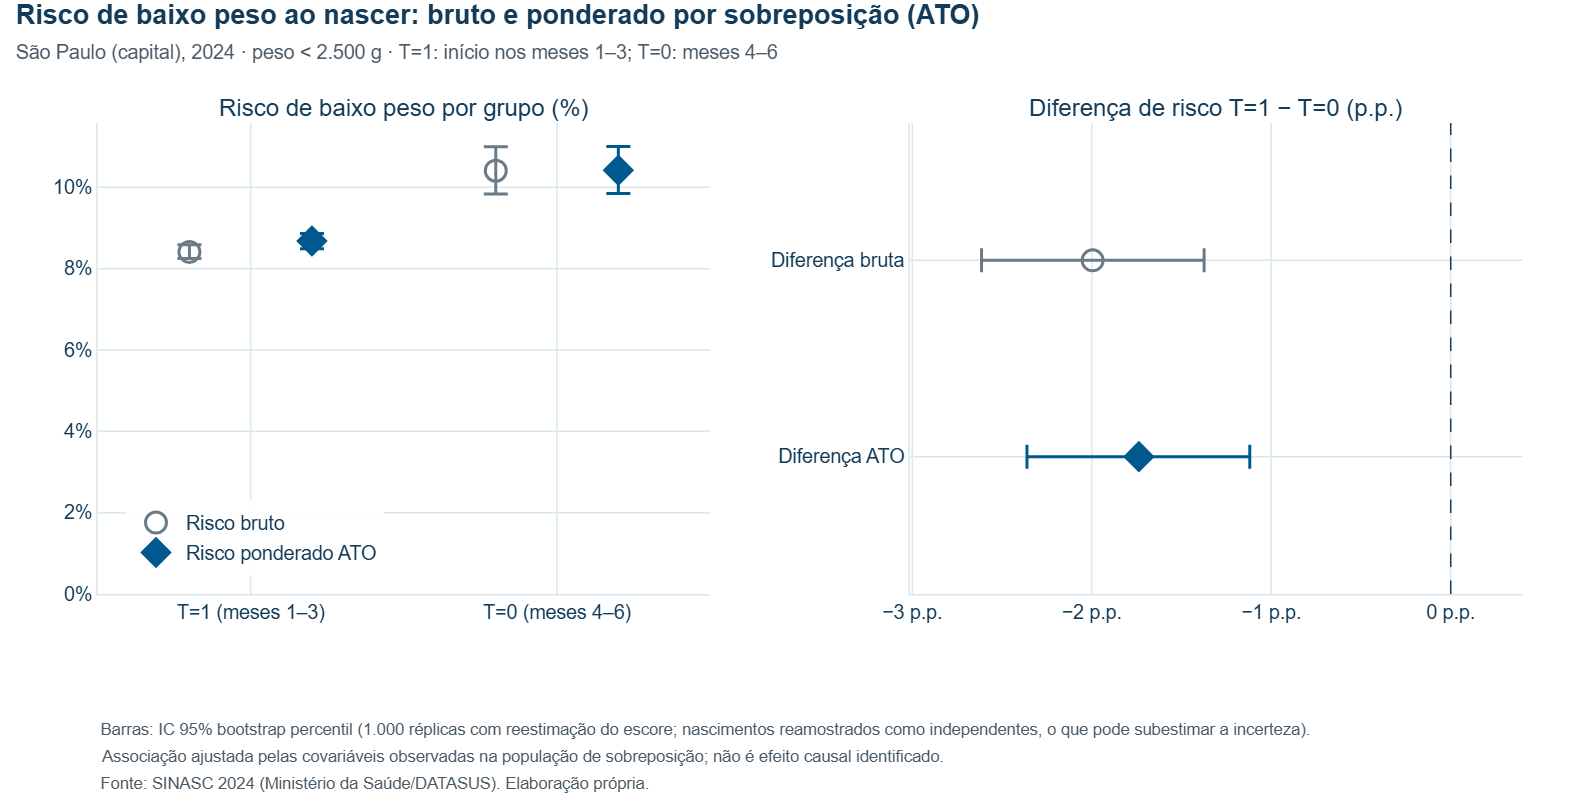

In [12]:
grupos = [(1, "T=1 (meses 1–3)"), (0, "T=0 (meses 4–6)")]
n_grupo = {1: n_t1, 0: n_t0}
n_efetivo = {1: ess.iloc[0], 0: ess.iloc[1]}
casos = {g: int(Y[T == g].sum()) for g, _ in grupos}
fig_risco = make_subplots(rows=1, cols=2, horizontal_spacing=0.14,
                          subplot_titles=("Risco de baixo peso por grupo (%)", "Diferença de risco T=1 − T=0 (p.p.)"))
for nome, risco, prefixo, cor, simbolo in [
        ("Risco bruto", risco_bruto, "bruto", COR_REFERENCIA, "circle-open"),
        ("Risco ponderado ATO", risco_ato, "ato", COR_T1, "diamond")]:
    pontos = [100 * risco[g] for g, _ in grupos]
    limites = [ic(f"{prefixo}_t{g}", 100) for g, _ in grupos]
    extra = "<br>Tamanho efetivo (Kish): %{customdata[3]}" if prefixo == "ato" else ""
    fig_risco.add_scatter(
        x=[r for _, r in grupos], y=pontos, name=nome, mode="markers", row=1, col=1,
        marker=dict(color=cor, symbol=simbolo, size=14, line=dict(width=2, color=cor)),
        error_y=dict(type="data", symmetric=False, thickness=2, width=8, color=cor,
                     array=[l[1] - p for p, l in zip(pontos, limites)],
                     arrayminus=[p - l[0] for p, l in zip(pontos, limites)]),
        customdata=[[f"{fmt(l[0], 2)} a {fmt(l[1], 2)}", fmt(n_grupo[g]), fmt(casos[g]), fmt(n_efetivo[g])]
                    for (g, _), l in zip(grupos, limites)],
        hovertemplate=("<b>%{x}</b><br>" + nome + ": %{y:.2f}%<br>IC 95%: %{customdata[0]}<br>"
                       "Nascimentos: %{customdata[1]} · casos: %{customdata[2]}" + extra + "<extra></extra>"))
for nome, valor, coluna, cor, simbolo in [("Diferença bruta", dif_bruta, "dif_bruta", COR_REFERENCIA, "circle-open"),
                                          ("Diferença ATO", dif_ato, "dif_ato", COR_T1, "diamond")]:
    lo, hi = ic(coluna)
    fig_risco.add_scatter(
        x=[valor], y=[nome], name=nome, mode="markers", row=1, col=2, showlegend=False,
        marker=dict(color=cor, symbol=simbolo, size=14, line=dict(width=2, color=cor)),
        error_x=dict(type="data", symmetric=False, thickness=2, width=8, color=cor,
                     array=[hi - valor], arrayminus=[valor - lo]),
        customdata=[[f"{fmt(lo, 2)} a {fmt(hi, 2)}"]],
        hovertemplate="<b>%{y}</b><br>%{x:.2f} p.p.<br>IC 95%: %{customdata[0]}<extra></extra>")
fig_risco.add_vline(x=0, line=dict(color=COR_TEXTO, dash="dash", width=1), row=1, col=2)
layout_academico(
    fig_risco, "Risco de baixo peso ao nascer: bruto e ponderado por sobreposição (ATO)",
    "São Paulo (capital), 2024 · peso < 2.500 g · T=1: início nos meses 1–3; T=0: meses 4–6",
    notas=["Barras: IC 95% bootstrap percentil (1.000 réplicas com reestimação do escore; nascimentos reamostrados como "
           "independentes, o que pode subestimar a incerteza).",
           "Associação ajustada pelas covariáveis observadas na população de sobreposição; não é efeito causal identificado.",
           FONTE_SINASC_2024],
    nome_arquivo="06_riscos_bruto_ato", altura=540)
fig_risco.update_layout(scattermode="group",
                        legend=dict(orientation="v", x=0.02, xanchor="left", y=0.04, yanchor="bottom",
                                    bgcolor="rgba(255,255,255,0.9)"))
fig_risco.update_yaxes(ticksuffix="%", rangemode="tozero", row=1, col=1)
fig_risco.update_yaxes(categoryorder="array", categoryarray=["Diferença ATO", "Diferença bruta"], range=[-0.7, 1.7],
                       row=1, col=2)
fig_risco.update_xaxes(range=[min(ic("dif_ato")[0], ic("dif_bruta")[0]) - 0.4, 0.4], ticksuffix=" p.p.",
                       row=1, col=2)
exibir_plotly(fig_risco)


## 6. Interpretação e limitações

Números recalculados a partir desta execução.

In [13]:
d_ic, b_ic = ic("dif_ato"), ic("dif_bruta")
reducao = 100 * (1 - dif_ato / dif_bruta)
conj = balanco.set_index(["variavel", "nivel"]).loc[("Situação conjugal (não ajustada)", "Casada")]
cruza_zero = d_ic[0] <= 0 <= d_ic[1]
direcao = "menor" if dif_ato < 0 else "maior"
texto = f"""
**Resultado.** Entre {fmt(n_total)} nascimentos (sem exclusões), o risco bruto de baixo peso foi {fmt(100 * risco_bruto[1], 2)}% em T=1 e {fmt(100 * risco_bruto[0], 2)}% em T=0: diferença bruta de **{fmt(dif_bruta, 2)} p.p.** (IC 95% {fmt(b_ic[0], 2)} a {fmt(b_ic[1], 2)}). Após a ponderação ATO, os riscos foram {fmt(100 * risco_ato[1], 2)}% e {fmt(100 * risco_ato[0], 2)}%: diferença ajustada de **{fmt(dif_ato, 2)} p.p.** (IC 95% bootstrap com reestimação do escore: {fmt(d_ic[0], 2)} a {fmt(d_ic[1], 2)}). {'O intervalo inclui zero.' if cruza_zero else 'O intervalo não inclui zero.'} O ajuste reduziu a magnitude da diferença em cerca de {fmt(reducao, 0)}%.

**Leitura correta.** Na população de sobreposição, e comparando grupos ponderados com distribuições aproximadamente iguais de idade, escolaridade, raça/cor, paridade e perdas fetais anteriores, o início do pré-natal nos meses 1–3 está **associado** a um risco de baixo peso {fmt(abs(dif_ato), 2)} p.p. {direcao} do que o início nos meses 4–6. Trata-se de **associação ajustada por covariáveis observadas sob ponderação ATO**, não de efeito causal identificado.

**Balanço e pesos.** Nas covariáveis ajustadas, o |SMD| máximo caiu de {fmt(ajustadas.smd_antes.abs().max(), 3)} para {fmt(ajustadas.smd_depois.abs().max(), 4)} — balanço aproximado nas covariáveis e nos termos do escore, esperado por construção, que não demonstra ausência de confundimento. Situação conjugal, deixada fora do modelo, segue desequilibrada: "casada" tem SMD {fmt(conj.smd_antes, 3)} antes e {fmt(conj.smd_depois, 3)} depois. Tamanho amostral efetivo: {fmt(ess.iloc[0])} em T=1 ({fmt(100 * ess.iloc[0] / n_t1, 1)}% de n) e {fmt(ess.iloc[1])} em T=0 ({fmt(100 * ess.iloc[1] / n_t0, 1)}% de n); pesos limitados a [0, 1], sem valores extremos.

**População-alvo.** O resultado vale para a população de sobreposição — nas covariáveis ajustadas (médias ponderadas de T=1, praticamente iguais às de T=0), idade média {fmt(perfil.loc[('Idade materna (anos)', 'média'), 'media_t1_pond'], 1)} anos e {fmt(100 * perfil.loc[('Escolaridade', 'Superior completo'), 'media_t1_pond'], 1)}% com superior completo, contra {fmt(total[('Idade materna (anos)', 'média')], 1)} anos e {fmt(100 * total[('Escolaridade', 'Superior completo')], 1)}% na população total; perfil mais próximo do grupo T=0 —, e não para todas as gestantes da capital (ATE) nem apenas para as que iniciaram cedo (ATT).

**Limitações que permanecem:**
- *Confundimento não observado:* renda, plano privado versus SUS, gravidez planejada, tabagismo, condições clínicas prévias e acesso à unidade de saúde não estão no SINASC e podem afetar tanto o início do pré-natal quanto o peso ao nascer. Situação conjugal, excluída por temporalidade, também fica sem ajuste, com desequilíbrio residual.
- *Dificuldade temporal da exposição:* `MESPRENAT` é registrado no parto; gestações mais curtas têm menos tempo para atingir um início tardio, e o baixo peso está ligado à prematuridade. Restringir T=0 aos meses 4–6 reduz a janela considerada para o início tardio, mas não foi demonstrado quanto isso altera o viés nem em que direção; o problema permanece em aberto (ver notebook 08).
- *Seleção por nascimento vivo:* perdas fetais da gestação atual não entram na população; se o início do pré-natal afeta a sobrevivência fetal, a comparação entre nascidos vivos pode ser enviesada. Não há vinculação individual SINASC–SIM que permita examinar essa seleção.
- *Mensuração das covariáveis:* todas registradas no parto; escolaridade pode mudar durante a gestação em adolescentes; perdas fetais anteriores misturam perdas espontâneas e abortos, com provável sub-registro.
- *Modelo e inferência:* o estimador depende de o escore logístico de efeitos principais (com idade quadrática) representar bem a relação entre X e T; não é duplamente robusto. O IC bootstrap reamostra nascimentos individuais como independentes; agrupamento por estabelecimento ou região e mães com mais de um parto no ano podem torná-lo estreito demais, e ele não incorpora vieses de confundimento, mensuração ou seleção.
- *Identificação:* sem estratégia de identificação além do ajuste por covariáveis observadas, o resultado é uma associação ajustada, não um efeito causal identificado.
"""
display(Markdown(texto))


**Resultado.** Entre 114.694 nascimentos (sem exclusões), o risco bruto de baixo peso foi 8,41% em T=1 e 10,41% em T=0: diferença bruta de **-2,00 p.p.** (IC 95% -2,61 a -1,37). Após a ponderação ATO, os riscos foram 8,68% e 10,42%: diferença ajustada de **-1,74 p.p.** (IC 95% bootstrap com reestimação do escore: -2,36 a -1,12). O intervalo não inclui zero. O ajuste reduziu a magnitude da diferença em cerca de 13%.

**Leitura correta.** Na população de sobreposição, e comparando grupos ponderados com distribuições aproximadamente iguais de idade, escolaridade, raça/cor, paridade e perdas fetais anteriores, o início do pré-natal nos meses 1–3 está **associado** a um risco de baixo peso 1,74 p.p. menor do que o início nos meses 4–6. Trata-se de **associação ajustada por covariáveis observadas sob ponderação ATO**, não de efeito causal identificado.

**Balanço e pesos.** Nas covariáveis ajustadas, o |SMD| máximo caiu de 0,452 para 0,0031 — balanço aproximado nas covariáveis e nos termos do escore, esperado por construção, que não demonstra ausência de confundimento. Situação conjugal, deixada fora do modelo, segue desequilibrada: "casada" tem SMD 0,421 antes e 0,194 depois. Tamanho amostral efetivo: 84.995 em T=1 (81,3% de n) e 10.096 em T=0 (99,8% de n); pesos limitados a [0, 1], sem valores extremos.

**População-alvo.** O resultado vale para a população de sobreposição — nas covariáveis ajustadas (médias ponderadas de T=1, praticamente iguais às de T=0), idade média 27,6 anos e 13,8% com superior completo, contra 29,1 anos e 29,5% na população total; perfil mais próximo do grupo T=0 —, e não para todas as gestantes da capital (ATE) nem apenas para as que iniciaram cedo (ATT).

**Limitações que permanecem:**
- *Confundimento não observado:* renda, plano privado versus SUS, gravidez planejada, tabagismo, condições clínicas prévias e acesso à unidade de saúde não estão no SINASC e podem afetar tanto o início do pré-natal quanto o peso ao nascer. Situação conjugal, excluída por temporalidade, também fica sem ajuste, com desequilíbrio residual.
- *Dificuldade temporal da exposição:* `MESPRENAT` é registrado no parto; gestações mais curtas têm menos tempo para atingir um início tardio, e o baixo peso está ligado à prematuridade. Restringir T=0 aos meses 4–6 reduz a janela considerada para o início tardio, mas não foi demonstrado quanto isso altera o viés nem em que direção; o problema permanece em aberto (ver notebook 08).
- *Seleção por nascimento vivo:* perdas fetais da gestação atual não entram na população; se o início do pré-natal afeta a sobrevivência fetal, a comparação entre nascidos vivos pode ser enviesada. Não há vinculação individual SINASC–SIM que permita examinar essa seleção.
- *Mensuração das covariáveis:* todas registradas no parto; escolaridade pode mudar durante a gestação em adolescentes; perdas fetais anteriores misturam perdas espontâneas e abortos, com provável sub-registro.
- *Modelo e inferência:* o estimador depende de o escore logístico de efeitos principais (com idade quadrática) representar bem a relação entre X e T; não é duplamente robusto. O IC bootstrap reamostra nascimentos individuais como independentes; agrupamento por estabelecimento ou região e mães com mais de um parto no ano podem torná-lo estreito demais, e ele não incorpora vieses de confundimento, mensuração ou seleção.
- *Identificação:* sem estratégia de identificação além do ajuste por covariáveis observadas, o resultado é uma associação ajustada, não um efeito causal identificado.


## 7. Análise de sensibilidade — situação conjugal

**Objetivo:** acrescentar `SITUACAO_CONJUGAL` ao propensity score, mantendo população, codificações, idade e idade², logística L2 (C=1), ajuste na amostra inteira, pesos ATO e ausência de recorte de suporte da especificação principal.

A situação conjugal é **registrada no parto**. Esta inclusão é exploratória: não se presume que a variável preceda o início do pré-natal. Mudar X modifica o escore e pode modificar a população-alvo ATO, proporcional a f(X)e(X)[1−e(X)]; uma mudança na estimativa **não pode ser atribuída exclusivamente à correção de confundimento**.

**Execução sequencial:** esta seção usa a amostra e os resultados produzidos nas seções anteriores, incluindo o bootstrap executado nesta sessão. Apenas o escore com situação conjugal é ajustado adicionalmente. Não se estima IC para a sensibilidade nem se aplica o IC principal à nova estimativa. Nenhum arquivo auxiliar é gravado.

In [14]:
# Referências produzidas pela análise principal nesta execução, em precisão completa.
riscos_principal_sens = np.array([100 * risco_ato[1], 100 * risco_ato[0]])
dif_principal_sens = dif_ato
ess_principal_sens = ess.to_numpy(float).tolist()
smd_principal_sens = pd.Series(
    balanco.smd_depois.abs().to_numpy(),
    index=[f"{v} — {n}" for v, n in zip(balanco.variavel, balanco.nivel)],
    name="|SMD| principal",
)
perfil_principal_sens = {
    (r.variavel, r.nivel): [
        fmt(r.media_t1_pond if r.nivel == "média" else 100 * r.media_t1_pond, 1)
        + ("" if r.nivel == "média" else "%"),
        fmt(r.media_t0_pond if r.nivel == "média" else 100 * r.media_t0_pond, 1)
        + ("" if r.nivel == "média" else "%"),
    ]
    for r in balanco.itertuples()
}
np.testing.assert_allclose(riscos_principal_sens[0] - riscos_principal_sens[1], dif_principal_sens, atol=1e-12, rtol=0)
print("Referência obtida dos objetos da análise principal nesta execução, sem leitura de saídas salvas.")

Referência obtida dos objetos da análise principal nesta execução, sem leitura de saídas salvas.


### Ajuste da sensibilidade

A mesma amostra ordenada é copiada da análise principal. A situação conjugal conserva as categorias e o indicador de ausência do contrato. O desfecho não entra no escore. A igualdade de chaves e de T/Y é verificada antes do ajuste.

In [15]:
dados_sens = dados.copy()
dados_sens["IDADEMAE_QUAD"] = dados_sens.IDADEMAE_NUM ** 2
T_sens = dados_sens.tratamento.to_numpy(dtype=int)
Y_sens = dados_sens.Y_BAIXO_PESO.to_numpy(dtype=int)
assert len(dados_sens) == 114694
assert (T_sens.sum(), (T_sens == 0).sum()) == (104576, 10118)
assert dados_sens.contador.is_unique and dados_sens.contador.notna().all()
assert dados_sens.peso_num.between(500, 6000).all()
assert np.array_equal(Y_sens, dados_sens.peso_num.lt(2500).to_numpy(int))
assert np.array_equal(T_sens, dados_sens.mesprenat_num.le(3).to_numpy(int))
assert dados_sens.IDADEMAE_NUM.notna().all()
assert dados_sens.contador.equals(dados.contador)
np.testing.assert_array_equal(T_sens, T)
np.testing.assert_array_equal(Y_sens, Y)

numericas_sens = ["IDADEMAE_NUM", "IDADEMAE_QUAD"]
categoricas_base_sens = ["ESCOLARIDADE_MAE", "RACA_COR_MAE", "PARIDADE_CAT", "PERDAS_FETAIS_CAT"]
categoricas_sens = categoricas_base_sens + ["SITUACAO_CONJUGAL"]
validar_colunas_propensity(numericas_sens + categoricas_sens)
X_sens = dados_sens[numericas_sens + categoricas_sens]
modelo_sens = construir_pipeline_propensity(numericas_sens, categoricas_sens)

with warnings.catch_warnings(record=True) as avisos_sens:
    warnings.simplefilter("always", ConvergenceWarning)
    modelo_sens.fit(X_sens, T_sens)  # Único modelo ajustado nesta seção.
assert not any(issubclass(a.category, ConvergenceWarning) for a in avisos_sens)

e_sens = modelo_sens.predict_proba(X_sens)[:, 1]
w_sens = np.where(T_sens == 1, 1 - e_sens, e_sens)
assert np.isfinite(e_sens).all() and ((e_sens > 0) & (e_sens < 1)).all()
assert ((w_sens > 0) & (w_sens < 1)).all()
risco_sens = {g: np.average(Y_sens[T_sens == g], weights=w_sens[T_sens == g])
              for g in (1, 0)}
dif_sens = 100 * (risco_sens[1] - risco_sens[0])
ess_sens = {g: w_sens[T_sens == g].sum() ** 2 / (w_sens[T_sens == g] ** 2).sum()
            for g in (1, 0)}
print(f"Novo escore convergiu em {modelo_sens['modelo'].n_iter_.max()} iterações.")
print("Mesma população; nenhuma exclusão ou recorte de suporte; bootstrap não executado.")

Novo escore convergiu em 89 iterações.
Mesma população; nenhuma exclusão ou recorte de suporte; bootstrap não executado.


### Comparação de estimativa, balanço e tamanho efetivo

SMD usa o mesmo denominador não ponderado da análise principal. O máximo global considera **o mesmo conjunto diagnóstico nos dois modelos**, incluindo situação conjugal e o indicador descritivo de idade 10–19 anos. Também se mostra o máximo nos termos efetivamente ajustados em cada modelo. Balanço pequeno nos termos da logística é esperado, mas com penalização L2 não se presume igualdade exata nem ausência de confundimento.

In [16]:
rotulos_sens = {
    "ESCOLARIDADE_MAE": ("Escolaridade", {"0": "Sem escolaridade", "1": "Fundamental I",
        "2": "Fundamental II", "3": "Médio", "4": "Superior incompleto", "5": "Superior completo"}),
    "RACA_COR_MAE": ("Raça/cor", {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena"}),
    "PARIDADE_CAT": ("Paridade", {"0": "Nulípara", "1": "Multípara"}),
    "PERDAS_FETAIS_CAT": ("Perdas fetais anteriores", {"0": "Nenhuma", "1": "Uma", "2_OU_MAIS": "Duas ou mais"}),
    # O rótulo antigo identifica a mesma linha salva; aqui a variável está ajustada.
    "SITUACAO_CONJUGAL": ("Situação conjugal (não ajustada)", {"1": "Solteira", "2": "Casada",
        "3": "Viúva", "4": "Separada/divorciada", "5": "União estável"}),
}
vetores_sens = {
    ("Idade materna (anos)", "média"): dados_sens.IDADEMAE_NUM.to_numpy(float),
    ("Idade materna²", "média"): dados_sens.IDADEMAE_QUAD.to_numpy(float),
    ("Idade materna (descritiva)", "10–19 anos"): dados_sens.IDADEMAE_NUM.le(19).to_numpy(float),
}
for campo_sens, (nome_sens, niveis_sens) in rotulos_sens.items():
    for nivel_sens in sorted(dados_sens[campo_sens].unique()):
        chave_sens = (nome_sens, niveis_sens.get(nivel_sens, "Ignorado/ausente"))
        vetores_sens[chave_sens] = dados_sens[campo_sens].eq(nivel_sens).to_numpy(float)

linhas_bal_sens = []
for chave_sens, vetor_sens in vetores_sens.items():
    v1_sens, v0_sens = vetor_sens[T_sens == 1], vetor_sens[T_sens == 0]
    dp_sens = np.sqrt((v1_sens.var(ddof=1) + v0_sens.var(ddof=1)) / 2)
    m1_sens = np.average(v1_sens, weights=w_sens[T_sens == 1])
    m0_sens = np.average(v0_sens, weights=w_sens[T_sens == 0])
    linhas_bal_sens.append({
        "variavel": chave_sens[0], "nivel": chave_sens[1],
        "media_t1": m1_sens, "media_t0": m0_sens,
        "smd": (m1_sens - m0_sens) / dp_sens if dp_sens else 0.0,
    })
balanco_sens = pd.DataFrame(linhas_bal_sens).set_index(["variavel", "nivel"])
rotulos_bal_sens = [f"{v} — {n}" for v, n in balanco_sens.index]
assert set(rotulos_bal_sens) == set(smd_principal_sens.index)
assert np.isfinite(balanco_sens.to_numpy()).all()
assert all(0 < ess_sens[g] <= (T_sens == g).sum() for g in (1, 0))

mascara_conj_principal_sens = smd_principal_sens.index.str.startswith("Situação conjugal")
mascara_base_principal_sens = ~smd_principal_sens.index.str.contains("não ajustada|descritiva")
conj_sens = balanco_sens.loc["Situação conjugal (não ajustada)"]
termos_sens = balanco_sens[
    ~balanco_sens.index.get_level_values("variavel").str.contains("descritiva")]
casada_sens = conj_sens.loc["Casada", "smd"]

def numero_sens(valor, casas=2):
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")

comparacao_sens = pd.DataFrame({
    "Principal (execução atual)": [
        numero_sens(dif_principal_sens),
        numero_sens(riscos_principal_sens[0]), numero_sens(riscos_principal_sens[1]),
        numero_sens(smd_principal_sens.max(), 4),
        numero_sens(smd_principal_sens[mascara_base_principal_sens].max(), 4),
        numero_sens(smd_principal_sens[mascara_conj_principal_sens].max(), 4),
        numero_sens(smd_principal_sens["Situação conjugal (não ajustada) — Casada"], 4),
        numero_sens(ess_principal_sens[0], 0), numero_sens(ess_principal_sens[1], 0),
    ],
    "Sensibilidade com situação conjugal": [
        numero_sens(dif_sens),
        numero_sens(100 * risco_sens[1]), numero_sens(100 * risco_sens[0]),
        numero_sens(balanco_sens.smd.abs().max(), 4),
        numero_sens(termos_sens.smd.abs().max(), 4),
        numero_sens(conj_sens.smd.abs().max(), 4),
        numero_sens(casada_sens, 4),
        numero_sens(ess_sens[1], 0), numero_sens(ess_sens[0], 0),
    ],
}, index=[
    "Diferença de riscos T=1 − T=0 (p.p.)",
    "Risco ponderado T=1 (%)", "Risco ponderado T=0 (%)",
    "Maior |SMD| — conjunto diagnóstico comum",
    "Maior |SMD| — termos ajustados de cada modelo",
    "Maior |SMD| — situação conjugal (todos os níveis)",
    "SMD — casada (T=1 − T=0)",
    "Tamanho efetivo T=1 (Kish)", "Tamanho efetivo T=0 (Kish)",
])
display(comparacao_sens)
maior_sens = balanco_sens.smd.abs().idxmax()
print("Maior desequilíbrio residual na sensibilidade:", maior_sens,
      "SMD =", numero_sens(balanco_sens.loc[maior_sens, "smd"], 4))
print("ESS calculado em precisão completa; arredondado somente para apresentação.")

,Principal (execução atual),Sensibilidade com situação conjugal
Diferença de riscos T=1 − T=0 (p.p.),"-1,74","-1,63"
Risco ponderado T=1 (%),"8,68","8,77"
Risco ponderado T=0 (%),"10,42","10,40"
Maior |SMD| — conjunto diagnóstico comum,"0,1945","0,0111"
Maior |SMD| — termos ajustados de cada modelo,"0,0031","0,0039"
Maior |SMD| — situação conjugal (todos os níveis),"0,1945","0,0014"
SMD — casada (T=1 − T=0),"0,1945","0,0001"
Tamanho efetivo T=1 (Kish),84.995,82.323
Tamanho efetivo T=0 (Kish),10.096,10.094


Maior desequilíbrio residual na sensibilidade: ('Idade materna (descritiva)', '10–19 anos') SMD = -0,0111
ESS calculado em precisão completa; arredondado somente para apresentação.


### Perfil básico das populações ponderadas

Valores principais obtidos do balanço desta execução e apresentados com uma casa decimal. As quatro colunas mostram os grupos separadamente; não se apresenta uma proporção única de casadas para o principal, onde essa variável permanece desequilibrada. As diferenças de perfil ajudam a caracterizar a mudança de alvo, mas não decompõem a mudança na associação.

In [17]:
itens_perfil_sens = [
    ("Idade materna (anos)", "média"),
    ("Idade materna (descritiva)", "10–19 anos"),
    ("Escolaridade", "Médio"),
    ("Escolaridade", "Superior completo"),
    ("Raça/cor", "Branca"),
    ("Paridade", "Nulípara"),
    ("Perdas fetais anteriores", "Nenhuma"),
    ("Situação conjugal (não ajustada)", "Casada"),
]
linhas_perfil_sens = []
for chave_sens in itens_perfil_sens:
    porcentagem_sens = chave_sens[1] != "média"
    fator_sens = 100 if porcentagem_sens else 1
    sufixo_sens = "%" if porcentagem_sens else ""
    valores_sens = balanco_sens.loc[chave_sens]
    rotulo_sens = " — ".join(chave_sens).replace(" (não ajustada)", "")
    linhas_perfil_sens.append({
        "Perfil": rotulo_sens,
        "Principal T=1": perfil_principal_sens[chave_sens][0],
        "Principal T=0": perfil_principal_sens[chave_sens][1],
        "Sensibilidade T=1": numero_sens(fator_sens * valores_sens.media_t1, 1) + sufixo_sens,
        "Sensibilidade T=0": numero_sens(fator_sens * valores_sens.media_t0, 1) + sufixo_sens,
    })
tabela_perfil_sens = pd.DataFrame(linhas_perfil_sens).set_index("Perfil")
display(tabela_perfil_sens)

,Principal T=1,Principal T=0,Sensibilidade T=1,Sensibilidade T=0
Perfil,,,,
Idade materna (anos) — média,"27,6","27,6","27,6","27,6"
Idade materna (descritiva) — 10–19 anos,"11,1%","11,3%","11,1%","11,4%"
Escolaridade — Médio,"65,2%","65,2%","65,2%","65,2%"
Escolaridade — Superior completo,"13,8%","13,8%","13,8%","13,8%"
Raça/cor — Branca,"36,7%","36,7%","36,7%","36,7%"
Paridade — Nulípara,"32,9%","32,9%","33,0%","33,0%"
Perdas fetais anteriores — Nenhuma,"79,2%","79,2%","79,2%","79,2%"
Situação conjugal — Casada,"27,1%","18,6%","19,2%","19,2%"


### Interpretação da sensibilidade

Comparação de estimativas pontuais, sem teste da diferença entre modelos e sem novo intervalo de confiança. As tabelas são suficientes para comparar os dois resultados; não se acrescenta gráfico redundante.

In [18]:
mudanca_pp_sens = dif_sens - dif_principal_sens
mudanca_magnitude_sens = abs(dif_sens) - abs(dif_principal_sens)
mudanca_relativa_sens = 100 * mudanca_magnitude_sens / abs(dif_principal_sens)
mesma_direcao_sens = np.sign(dif_sens) == np.sign(dif_principal_sens)
acao_sens = "aumento" if mudanca_magnitude_sens > 0 else "redução"
texto_final_sens = f"""
**Resultado:** principal **{numero_sens(dif_principal_sens)} p.p.**
(IC95% desta execução: {numero_sens(ic("dif_ato")[0])} a {numero_sens(ic("dif_ato")[1])}); sensibilidade **{numero_sens(dif_sens)} p.p.**, sem novo IC.
A mudança assinada é **{numero_sens(mudanca_pp_sens, 3)} p.p.**,
com {acao_sens} de **{numero_sens(abs(mudanca_magnitude_sens), 3)} p.p.**
na magnitude absoluta (**{numero_sens(abs(mudanca_relativa_sens), 1)}%**).
{'A direção descritiva permanece: menor risco ponderado em T=1.' if mesma_direcao_sens and dif_sens < 0 else 'Verificar a direção na tabela; não presumir estabilidade.'}
A semelhança pontual não constitui teste de equivalência ou robustez causal.

**Balanço:** máximo global |SMD| de {numero_sens(smd_principal_sens.max(), 4)}
para {numero_sens(balanco_sens.smd.abs().max(), 4)};
casada: de {numero_sens(smd_principal_sens['Situação conjugal (não ajustada) — Casada'], 4)}
para {numero_sens(casada_sens, 4)}.
ESS: T=1 de {numero_sens(ess_principal_sens[0], 0)} para {numero_sens(ess_sens[1], 0)};
T=0 de {numero_sens(ess_principal_sens[1], 0)} para {numero_sens(ess_sens[0], 0)}.
A melhora de balanço na variável agora incluída é esperada pelo ajuste.

**Interpretação:** incluir situação conjugal altera os pesos e pode alterar a
população-alvo ATO. A diferença entre estimativas mistura mudança de ajuste e
mudança de população; não pode ser atribuída exclusivamente à correção de
confundimento. Situação conjugal é medida no parto: sua condição pré-exposição
não está demonstrada. Esta é uma **sensibilidade exploratória de associação
ajustada**, não um efeito causal identificado. A análise principal permanece
inalterada; o bootstrap principal foi executado nesta sessão e não há bootstrap adicional para a sensibilidade.
"""
display(Markdown(texto_final_sens))


**Resultado:** principal **-1,74 p.p.**
(IC95% desta execução: -2,36 a -1,12); sensibilidade **-1,63 p.p.**, sem novo IC.
A mudança assinada é **0,107 p.p.**,
com redução de **0,107 p.p.**
na magnitude absoluta (**6,1%**).
A direção descritiva permanece: menor risco ponderado em T=1.
A semelhança pontual não constitui teste de equivalência ou robustez causal.

**Balanço:** máximo global |SMD| de 0,1945
para 0,0111;
casada: de 0,1945
para 0,0001.
ESS: T=1 de 84.995 para 82.323;
T=0 de 10.096 para 10.094.
A melhora de balanço na variável agora incluída é esperada pelo ajuste.

**Interpretação:** incluir situação conjugal altera os pesos e pode alterar a
população-alvo ATO. A diferença entre estimativas mistura mudança de ajuste e
mudança de população; não pode ser atribuída exclusivamente à correção de
confundimento. Situação conjugal é medida no parto: sua condição pré-exposição
não está demonstrada. Esta é uma **sensibilidade exploratória de associação
ajustada**, não um efeito causal identificado. A análise principal permanece
inalterada; o bootstrap principal foi executado nesta sessão e não há bootstrap adicional para a sensibilidade.


## 8. Reconciliação e conclusão

Contagens exigem igualdade exata. Para riscos, diferenças e IC publicados com duas casas, exige-se a mesma apresentação nessa precisão; ESS publicado inteiro é conferido no inteiro mais próximo. A comparação em precisão completa das saídas anteriores é feita na reconstrução, fora do fluxo científico. As verificações abaixo não substituem os cálculos e interrompem a execução em caso de divergência.

A estimativa permanece uma associação ajustada: bom balanço não remove confundimento não observado, temporalidade imperfeita ou seleção de nascidos vivos. A sensibilidade não identifica qual componente explica a mudança na estimativa.

**Reconciliação da reconstrução:** as contagens, riscos, ESS, balanço e sensibilidade reproduziram as saídas originais. As 1.000 réplicas convergiram e os IC reproduziram a precisão publicada. No gráfico anterior, os extremos horizontais do IC tinham sido reconstruídos a partir de valores arredondados. Nesta execução, o IC ATO é −2,3609150068 a −1,1195484985 p.p. e o bruto é −2,6140699366 a −1,3739930724 p.p.; as barras agora usam os percentis completos. A diferença gráfica máxima é 0,004070 p.p. e decorre da precisão de apresentação, sem alteração de amostra, semente, reamostragem ou modelo.

In [19]:
assert B == 1000 and SEMENTE == 20240925
assert len(boot) == 1000 and boot.convergiu.eq(1).all()
assert [fmt(100 * risco_ato[g], 2) for g in (1, 0)] == ["8,68", "10,42"]
assert fmt(dif_ato, 2) == "-1,74"
assert [fmt(v, 2) for v in ic("dif_ato")] == ["-2,36", "-1,12"]
assert [fmt(v) for v in ess] == ["84.995", "10.096"]
assert fmt(dif_sens, 2) == "-1,63"
print("Referências publicadas conferidas: população, riscos, ATO, IC, ESS e sensibilidade.")

Referências publicadas conferidas: população, riscos, ATO, IC, ESS e sensibilidade.
